# 🏏 CricketIQ 2.0 — Notebook 03: Exploratory Data Analysis (EDA)
## BCA Machine Learning Project Pipeline — Phase 3

**Objective:**
1. Analyze historical trends in IPL season volume and scoring patterns.
2. Uncover ground-specific chasing biases across major Indian stadiums.
3. Visualize all-time leading run-scorers and leading wicket-takers.


In [1]:
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams['figure.figsize'] = (11, 5)

BASE_DIR = Path("..").resolve() if Path("..").resolve().name == "CricketIQ 2.0" else Path(".").resolve()
sys.path.insert(0, str(BASE_DIR))

from src.data_loader import load_data
matches, deliveries = load_data(BASE_DIR)


### 1. Matches Played Per Season (2008–2024)

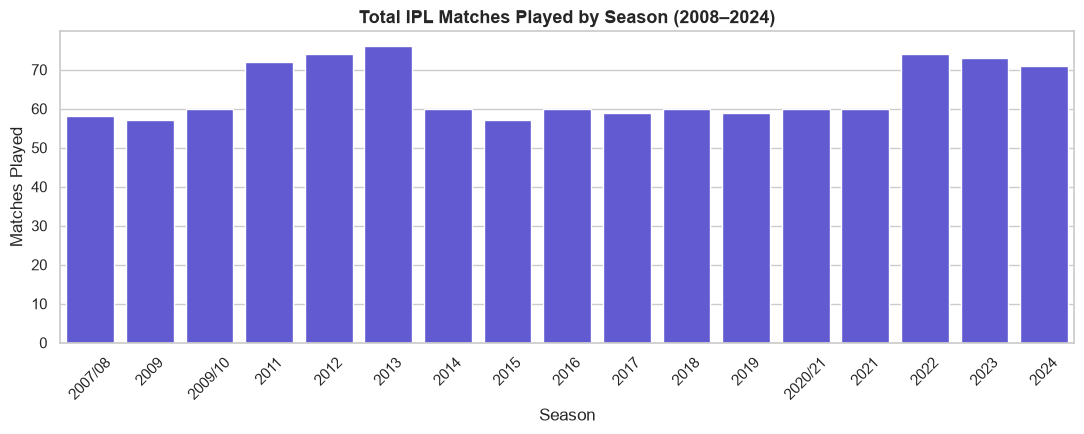

In [2]:
plt.figure(figsize=(11, 4.5))
season_counts = matches.groupby('season')['id'].count()
sns.barplot(x=season_counts.index, y=season_counts.values, color='#4f46e5')
plt.title('Total IPL Matches Played by Season (2008–2024)', fontweight='bold', fontsize=13)
plt.xlabel('Season')
plt.ylabel('Matches Played')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


### 2. Toss Decision Evolution: Batting vs Chasing Trends

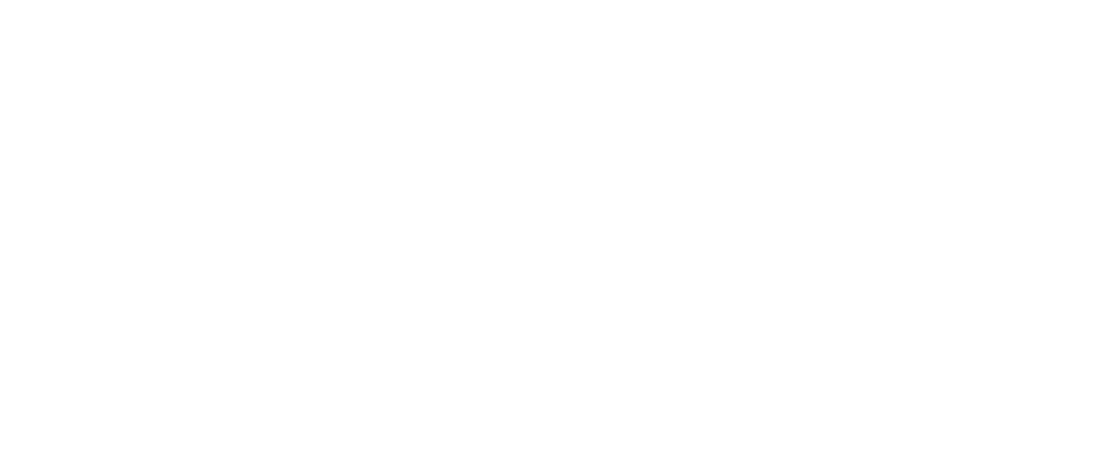

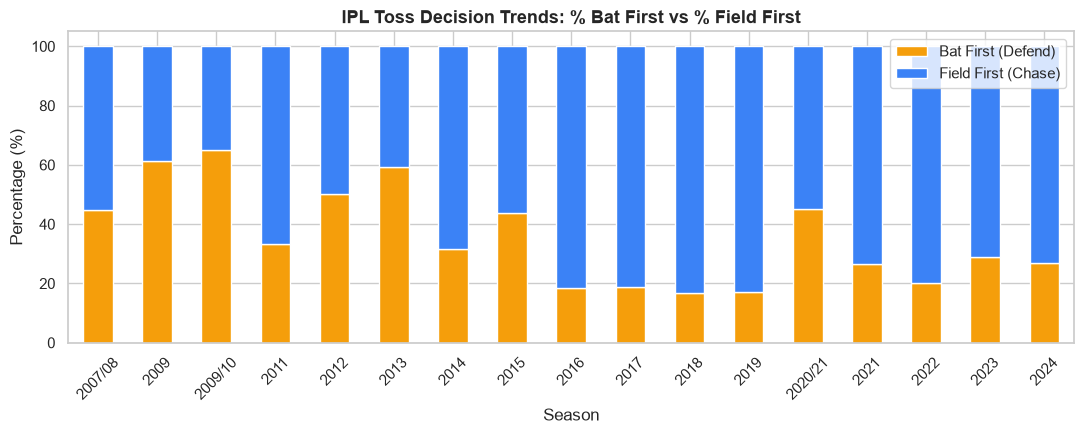

In [3]:
plt.figure(figsize=(11, 4.5))
toss_trends = pd.crosstab(matches['season'], matches['toss_decision'], normalize='index') * 100
toss_trends.plot(kind='bar', stacked=True, color=['#f59e0b', '#3b82f6'], figsize=(11, 4.5))
plt.title('IPL Toss Decision Trends: % Bat First vs % Field First', fontweight='bold', fontsize=13)
plt.xlabel('Season')
plt.ylabel('Percentage (%)')
plt.legend(['Bat First (Defend)', 'Field First (Chase)'], loc='upper right')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


### 3. Ground Chasing Bias Across Top 10 Stadiums

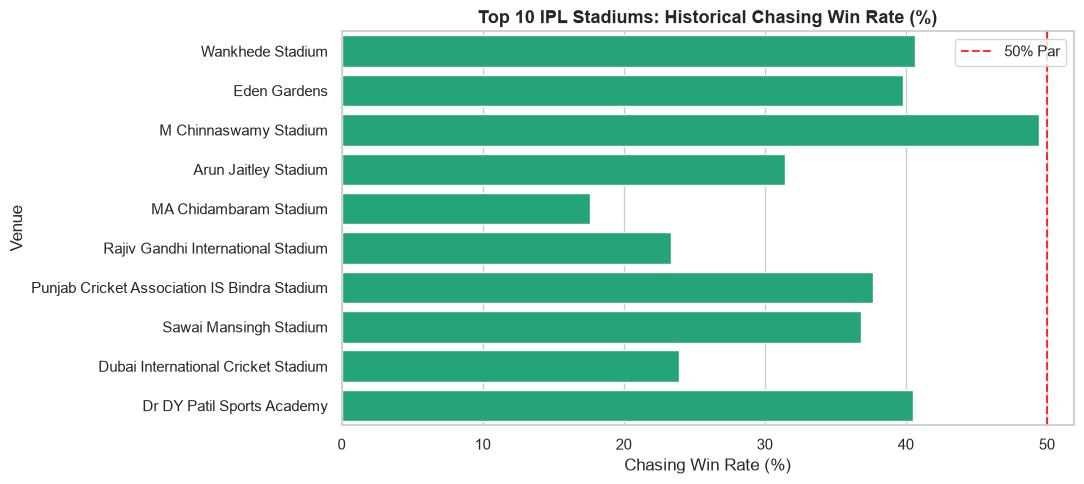

In [4]:
venue_summary = matches.groupby('venue').agg(
    total_matches=('id', 'count'),
    chase_wins=('winner', lambda s: (matches.loc[s.index, 'toss_decision'].eq('field') & matches.loc[s.index, 'winner'].eq(matches.loc[s.index, 'toss_winner'])).sum())
).reset_index()

venue_summary = venue_summary.sort_values('total_matches', ascending=False).head(10)
venue_summary['chase_win_pct'] = (venue_summary['chase_wins'] / venue_summary['total_matches']) * 100

plt.figure(figsize=(11, 5))
sns.barplot(data=venue_summary, y='venue', x='chase_win_pct', color='#10b981')
plt.axvline(50, color='red', linestyle='--', alpha=0.8, label='50% Par')
plt.title('Top 10 IPL Stadiums: Historical Chasing Win Rate (%)', fontweight='bold', fontsize=13)
plt.xlabel('Chasing Win Rate (%)')
plt.ylabel('Venue')
plt.legend()
plt.tight_layout()
plt.show()


### 4. Top 10 All-Time IPL Batsmen and Bowlers

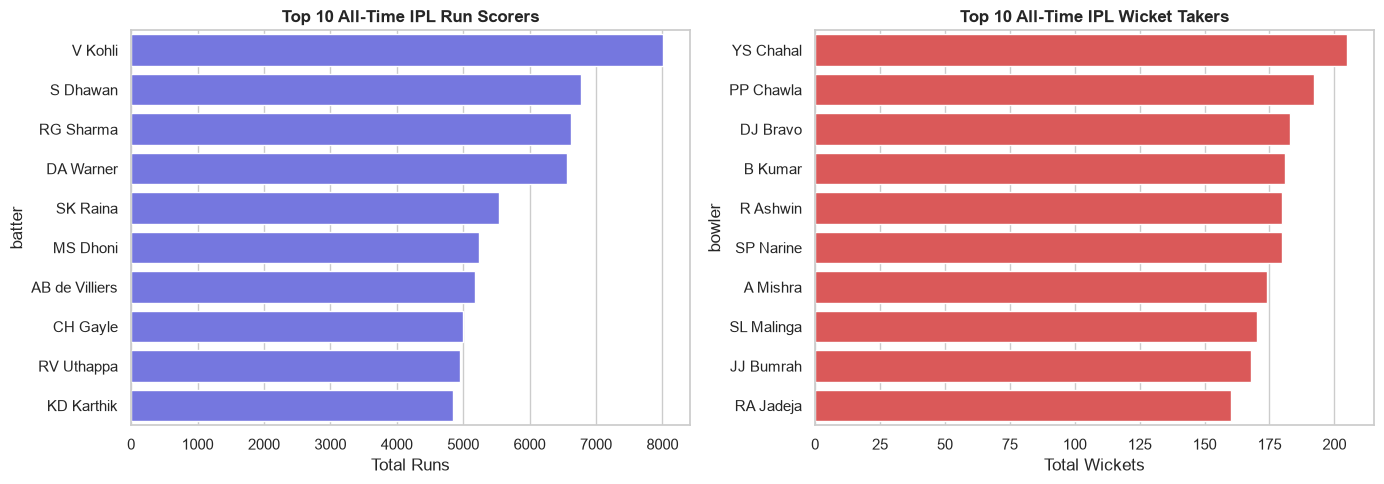

In [5]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Top Batters
top_bat = deliveries.groupby('batter')['batsman_runs'].sum().sort_values(ascending=False).head(10)
sns.barplot(x=top_bat.values, y=top_bat.index, ax=ax1, color='#6366f1')
ax1.set_title('Top 10 All-Time IPL Run Scorers', fontweight='bold')
ax1.set_xlabel('Total Runs')

# Top Bowlers
valid_wickets = deliveries[
    (deliveries['is_wicket'] == 1) & 
    (~deliveries['dismissal_kind'].isin(['run out', 'retired hurt', 'obstructing the field']))
]
top_bowl = valid_wickets.groupby('bowler')['is_wicket'].sum().sort_values(ascending=False).head(10)
sns.barplot(x=top_bowl.values, y=top_bowl.index, ax=ax2, color='#ef4444')
ax2.set_title('Top 10 All-Time IPL Wicket Takers', fontweight='bold')
ax2.set_xlabel('Total Wickets')

plt.tight_layout()
plt.show()
